# 02 — System Performance Trends

## Purpose
Analyse NHS A&E system-level performance and pressure trends across the validated 25-month period from September 2024 to September 2026.

This notebook consumes the controlled DuckDB analytical layer. It does **not** recreate ingestion, transformation, reconciliation, or KPI engineering logic from `01_source_data_profile.ipynb` or the reusable project modules.

### Initial notebook gate
Before analytical work begins, this notebook validates:
- the project and database paths;
- the read-only DuckDB connection;
- the expected core table and analytical views;
- the 4,918-row, 25-month provider-month source grain;
- the 25-row monthly KPI view;
- the 25-row monthly pressure view.

Only after these checks pass should system-level trend analysis continue.


## 1. Imports and project configuration

Use project-owned configuration and database connection utilities so the notebook remains reproducible and independent of the terminal working directory.


In [90]:

import pandas as pd

from nhs_ae.config import PROJECT_PATHS
from nhs_ae.database.connection import database_connection

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")


## 2. Validate project and analytical database paths

This gate confirms that the validated master dataset, SQL directory, and persistent DuckDB analytical database are available before any query is executed.


In [91]:
database_path = PROJECT_PATHS.database_file
master_dataset_path = PROJECT_PATHS.master_dataset
sql_path = PROJECT_PATHS.sql

assert PROJECT_PATHS.root.exists(), "Project root does not exist."
assert master_dataset_path.exists(), "Validated master dataset is missing."
assert sql_path.exists(), "SQL directory is missing."
assert database_path.exists(), "DuckDB analytical database is missing."

print("PROJECT PATH VALIDATION: PASS")
print("Project root:", PROJECT_PATHS.root)
print("Master dataset:", master_dataset_path)
print("SQL directory:", sql_path)
print("DuckDB database:", database_path)


PROJECT PATH VALIDATION: PASS
Project root: C:\nhs_ae_analytics
Master dataset: C:\nhs_ae_analytics\data\processed\nhs_ae_provider_2024_09_to_2026_09.csv
SQL directory: C:\nhs_ae_analytics\sql
DuckDB database: C:\nhs_ae_analytics\data\database\nhs_ae.duckdb


## 3. Validate the read-only DuckDB connection

Analytical notebooks should query the established database without modifying it. The connection is therefore opened in read-only mode.


In [92]:
with database_connection(read_only=True) as connection:
    database_version = connection.execute("SELECT version()").fetchone()

assert database_version is not None

print("DUCKDB CONNECTION: PASS")
print("DuckDB version:", database_version[0])


DUCKDB CONNECTION: PASS
DuckDB version: v2.0.0


## 4. Discover and validate analytical database objects

The notebook requires one controlled core table and the five reconciled analytical views established in the SQL layer.


In [93]:
expected_objects = {
    ("core", "provider_monthly", "BASE TABLE"),
    ("analytics", "monthly_kpis", "VIEW"),
    ("analytics", "monthly_pressure", "VIEW"),
    ("analytics", "provider_summary", "VIEW"),
    ("analytics", "provider_change", "VIEW"),
    ("analytics", "provider_pressure", "VIEW"),
}

with database_connection(read_only=True) as connection:
    database_objects = connection.execute(
        """
        SELECT table_schema, table_name, table_type
        FROM information_schema.tables
        WHERE table_schema IN ('core', 'analytics')
        ORDER BY table_schema, table_name
        """
    ).df()

actual_objects = set(
    database_objects[["table_schema", "table_name", "table_type"]]
    .itertuples(index=False, name=None)
)

missing_objects = expected_objects - actual_objects
assert not missing_objects, f"Missing database objects: {sorted(missing_objects)}"

print("ANALYTICAL DATABASE OBJECT VALIDATION: PASS")
database_objects


ANALYTICAL DATABASE OBJECT VALIDATION: PASS


,table_schema,table_name,table_type
0,analytics,monthly_kpis,VIEW
1,analytics,monthly_pressure,VIEW
2,analytics,provider_change,VIEW
3,analytics,provider_pressure,VIEW
4,analytics,provider_summary,VIEW
5,core,provider_monthly,BASE TABLE


## 5. Validate the provider-month analytical source

`core.provider_monthly` is the controlled provider-level source for the analytical SQL layer. Its expected grain is one row per provider and reporting month.


In [94]:
with database_connection(read_only=True) as connection:
    core_validation = connection.execute(
        """
        SELECT
            COUNT(*) AS row_count,
            COUNT(DISTINCT reporting_month) AS month_count,
            COUNT(DISTINCT org_code) AS provider_count,
            MIN(reporting_month) AS start_month,
            MAX(reporting_month) AS end_month,
            COUNT(*) - COUNT(
                DISTINCT (reporting_month, org_code)
            ) AS duplicate_provider_month_keys
        FROM core.provider_monthly
        """
    ).df()

validation = core_validation.iloc[0]

assert validation["row_count"] == 4_918
assert validation["month_count"] == 25
assert validation["provider_count"] == 207
assert str(validation["start_month"])[:10] == "2024-09-01"
assert str(validation["end_month"])[:10] == "2026-09-01"
assert validation["duplicate_provider_month_keys"] == 0

print("CORE PROVIDER-MONTH VALIDATION: PASS")
core_validation


CORE PROVIDER-MONTH VALIDATION: PASS


,row_count,month_count,provider_count,start_month,end_month,duplicate_provider_month_keys
0,4918,25,207,2024-09-01,2026-09-01,0


## 6. Load and validate monthly KPI analytical source

The system-performance analysis uses `analytics.monthly_kpis`, already independently reconciled against the controlled Python `monthly_kpis` output.


In [95]:
with database_connection(read_only=True) as connection:
    monthly_kpis = connection.execute(
        """
        SELECT *
        FROM analytics.monthly_kpis
        ORDER BY reporting_month
        """
    ).df()

monthly_kpis["reporting_month"] = pd.to_datetime(
    monthly_kpis["reporting_month"]
)

assert len(monthly_kpis) == 25
assert len(monthly_kpis.columns) == 7
assert monthly_kpis["reporting_month"].is_unique
assert monthly_kpis["reporting_month"].min() == pd.Timestamp("2024-09-01")
assert monthly_kpis["reporting_month"].max() == pd.Timestamp("2026-09-01")

print("MONTHLY KPI SOURCE VALIDATION: PASS")
print("Rows:", len(monthly_kpis))
print("Columns:", len(monthly_kpis.columns))
monthly_kpis.head()


MONTHLY KPI SOURCE VALIDATION: PASS
Rows: 25
Columns: 7


,reporting_month,total_attendances,emergency_admissions,attendance_monthly_change,admission_monthly_change,attendance_year_on_year_change,admission_year_on_year_change
0,2024-09-01,"2,214,217.0000","530,824.0000",NaN,NaN,NaN,NaN
1,2024-10-01,"2,360,536.0000","567,448.0000",0.0661,0.0690,NaN,NaN
2,2024-11-01,"2,314,998.0000","552,161.0000",-0.0193,-0.0269,NaN,NaN
3,2024-12-01,"2,345,934.0000","552,592.0000",0.0134,0.0008,NaN,NaN
4,2025-01-01,"2,218,130.0000","548,775.0000",-0.0545,-0.0069,NaN,NaN


## 7. Load and validate monthly pressure analytical source

`analytics.monthly_pressure` provides the controlled system-level four-hour breach and decision-to-admit waiting measures used in the pressure and flow analysis.


In [96]:
with database_connection(read_only=True) as connection:
    monthly_pressure = connection.execute(
        """
        SELECT *
        FROM analytics.monthly_pressure
        ORDER BY reporting_month
        """
    ).df()

monthly_pressure["reporting_month"] = pd.to_datetime(
    monthly_pressure["reporting_month"]
)

assert len(monthly_pressure) == 25
assert len(monthly_pressure.columns) == 13
assert monthly_pressure["reporting_month"].is_unique
assert monthly_pressure["reporting_month"].min() == pd.Timestamp("2024-09-01")
assert monthly_pressure["reporting_month"].max() == pd.Timestamp("2026-09-01")

print("MONTHLY PRESSURE SOURCE VALIDATION: PASS")
print("Rows:", len(monthly_pressure))
print("Columns:", len(monthly_pressure.columns))
monthly_pressure.head()


MONTHLY PRESSURE SOURCE VALIDATION: PASS
Rows: 25
Columns: 13


,reporting_month,four_hour_breaches,dta_waits_4_12hrs,dta_waits_12plus_hrs,total_dta_waits_4plus_hrs,four_hour_breaches_monthly_change,four_hour_breaches_year_on_year_change,dta_waits_4_12hrs_monthly_change,dta_waits_4_12hrs_year_on_year_change,dta_waits_12plus_hrs_monthly_change,dta_waits_12plus_hrs_year_on_year_change,total_dta_waits_4plus_hrs_monthly_change,total_dta_waits_4plus_hrs_year_on_year_change
0,2024-09-01,"570,888.0000","91,752.0000","38,880.0000","130,632.0000",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2024-10-01,"635,342.0000","99,172.0000","49,616.0000","148,788.0000",0.1129,NaN,0.0809,NaN,0.2761,NaN,0.1390,NaN
2,2024-11-01,"643,996.0000","94,991.0000","45,791.0000","140,782.0000",0.0136,NaN,-0.0422,NaN,-0.0771,NaN,-0.0538,NaN
3,2024-12-01,"677,473.0000","100,482.0000","54,207.0000","154,689.0000",0.0520,NaN,0.0578,NaN,0.1838,NaN,0.0988,NaN
4,2025-01-01,"598,746.0000","98,053.0000","61,529.0000","159,582.0000",-0.1162,NaN,-0.0242,NaN,0.1351,NaN,0.0316,NaN


## 8. Cross-source analytical period validation

The monthly KPI and pressure views must describe the same 25 reporting months in the same chronological order before they are combined or compared.


In [97]:
assert monthly_kpis["reporting_month"].equals(
    monthly_pressure["reporting_month"]
)

analysis_months = monthly_kpis["reporting_month"].copy()

print("CROSS-SOURCE PERIOD VALIDATION: PASS")
print("Months:", len(analysis_months))
print("Start:", analysis_months.min().date())
print("End:", analysis_months.max().date())


CROSS-SOURCE PERIOD VALIDATION: PASS
Months: 25
Start: 2024-09-01
End: 2026-09-01


## 9. Analytical-source gate complete

The DuckDB connection and system-level analytical sources are now validated. The next cells in this notebook should proceed from these controlled DataFrames into descriptive system performance, trend, year-on-year, pressure, and patient-flow analysis.

**Validated notebook inputs:**
- `monthly_kpis`: 25 months × 7 columns
- `monthly_pressure`: 25 months × 13 columns

No raw-file ingestion or KPI derivation should be duplicated in this notebook.


## 10. System attendance and emergency admission trends

We now move from source validation into descriptive system-level analysis.

The first analytical section examines:

- monthly A&E attendance volume;
- monthly emergency admission volume;
- month-on-month change;
- year-on-year change.

All measures come directly from the reconciled `analytics.monthly_kpis` DuckDB view.

Baseline descriptive statistics

In [98]:
system_kpi_summary = (
    monthly_kpis[
        [
            "total_attendances",
            "emergency_admissions",
        ]
    ]
    .agg(
        [
            "min",
            "max",
            "mean",
            "median",
            "std",
        ]
    )
    .T
)

system_kpi_summary["total_25_month_period"] = [
    monthly_kpis["total_attendances"].sum(),
    monthly_kpis["emergency_admissions"].sum(),
]

system_kpi_summary

,min,max,mean,median,std,total_25_month_period
total_attendances,"2,088,071.0000","2,487,580.0000","2,336,915.6000","2,345,934.0000","98,370.0603","58,422,890.0000"
emergency_admissions,"493,015.0000","567,448.0000","537,828.7200","536,158.0000","17,623.4937","13,445,718.0000"


Identify minimum and maximum months

In [99]:
attendance_min = monthly_kpis.loc[
    monthly_kpis["total_attendances"].idxmin()
]

attendance_max = monthly_kpis.loc[
    monthly_kpis["total_attendances"].idxmax()
]

admission_min = monthly_kpis.loc[
    monthly_kpis["emergency_admissions"].idxmin()
]

admission_max = monthly_kpis.loc[
    monthly_kpis["emergency_admissions"].idxmax()
]

system_extremes = pd.DataFrame(
    {
        "measure": [
            "Minimum attendances",
            "Maximum attendances",
            "Minimum emergency admissions",
            "Maximum emergency admissions",
        ],
        "reporting_month": [
            attendance_min["reporting_month"],
            attendance_max["reporting_month"],
            admission_min["reporting_month"],
            admission_max["reporting_month"],
        ],
        "value": [
            attendance_min["total_attendances"],
            attendance_max["total_attendances"],
            admission_min["emergency_admissions"],
            admission_max["emergency_admissions"],
        ],
    }
)

system_extremes

,measure,reporting_month,value
0,Minimum attendances,2025-02-01,"2,088,071.0000"
1,Maximum attendances,2026-07-01,"2,487,580.0000"
2,Minimum emergency admissions,2026-02-01,"493,015.0000"
3,Maximum emergency admissions,2024-10-01,"567,448.0000"


### Interpretation checkpoint

The descriptive tables establish the overall scale, central tendency, variability, and observed monthly extremes.

At this stage, minimum and maximum months are descriptive observations only. No causal explanation should be assigned without additional evidence.

Attendance trend visualisation

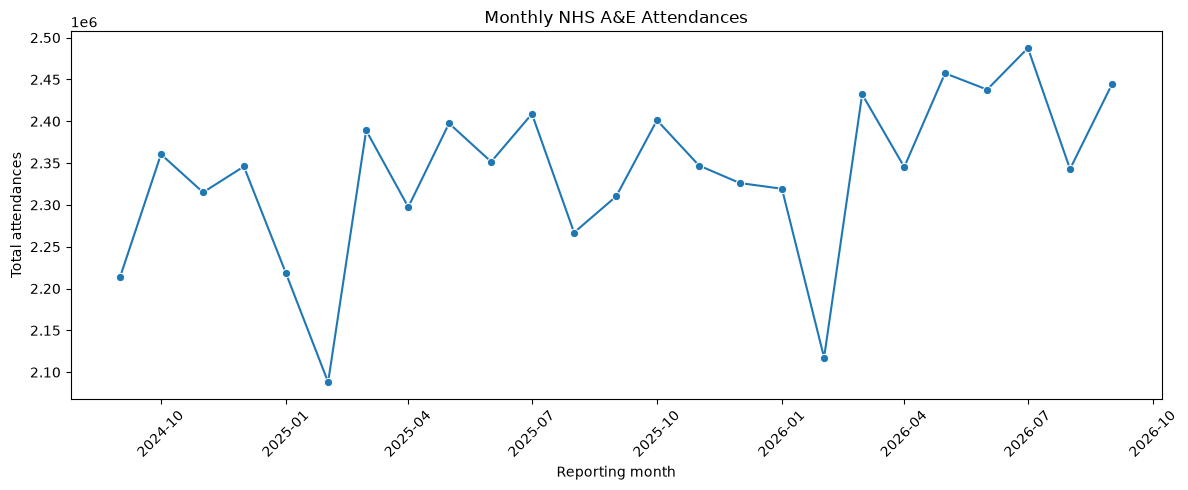

In [100]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(figsize=(12, 5))

sns.lineplot(
    data=monthly_kpis,
    x="reporting_month",
    y="total_attendances",
    marker="o",
    ax=ax,
)

ax.set_title("Monthly NHS A&E Attendances")
ax.set_xlabel("Reporting month")
ax.set_ylabel("Total attendances")
ax.tick_params(axis="x", rotation=45)

fig.tight_layout()
plt.show()


Emergency admissions trend

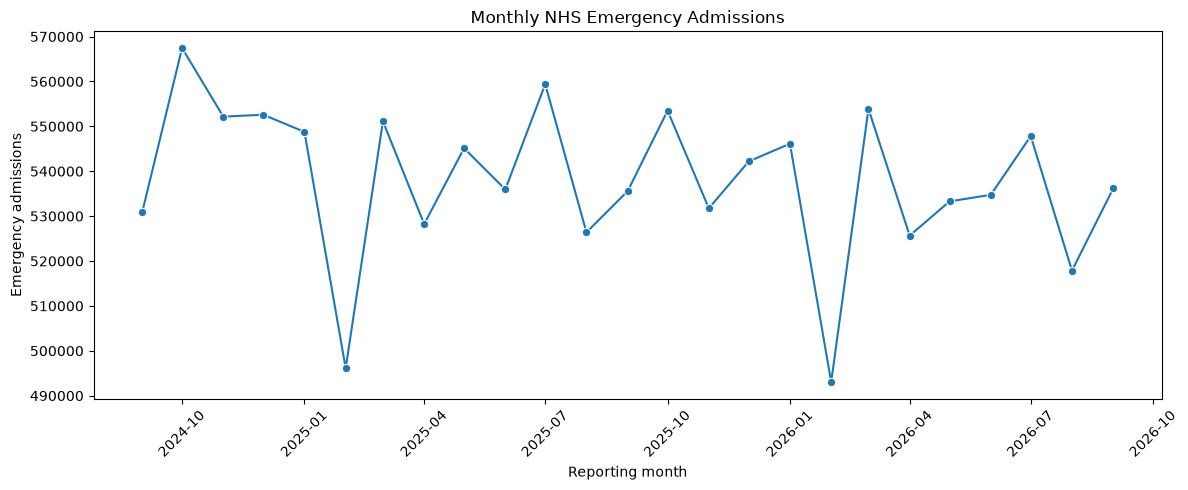

In [101]:
fig, ax = plt.subplots(figsize=(12, 5))

sns.lineplot(
    data=monthly_kpis,
    x="reporting_month",
    y="emergency_admissions",
    marker="o",
    ax=ax,
)

ax.set_title("Monthly NHS Emergency Admissions")
ax.set_xlabel("Reporting month")
ax.set_ylabel("Emergency admissions")
ax.tick_params(axis="x", rotation=45)

fig.tight_layout()
plt.show()

## 11. Month-on-month system change

Absolute monthly volumes show system scale. Percentage change provides a complementary view of short-term movement.

Month-on-month values should be interpreted as changes relative to the immediately preceding reporting month. The first month therefore has no valid month-on-month comparator.

Month-on-month movements

In [102]:
monthly_change = monthly_kpis[
    [
        "reporting_month",
        "attendance_monthly_change",
        "admission_monthly_change",
    ]
].copy()

monthly_change[
    [
        "attendance_monthly_change",
        "admission_monthly_change",
    ]
] *= 100

monthly_change

,reporting_month,attendance_monthly_change,admission_monthly_change
0,2024-09-01,NaN,NaN
1,2024-10-01,6.6082,6.8995
2,2024-11-01,-1.9291,-2.6940
3,2024-12-01,1.3363,0.0781
4,2025-01-01,-5.4479,-0.6907
5,2025-02-01,-5.8635,-9.5996
6,2025-03-01,14.4149,11.0934
7,2025-04-01,-3.8359,-4.1549
8,2025-05-01,4.3574,3.1990
9,2025-06-01,-1.9165,-1.6853


Month-on-month visualisation

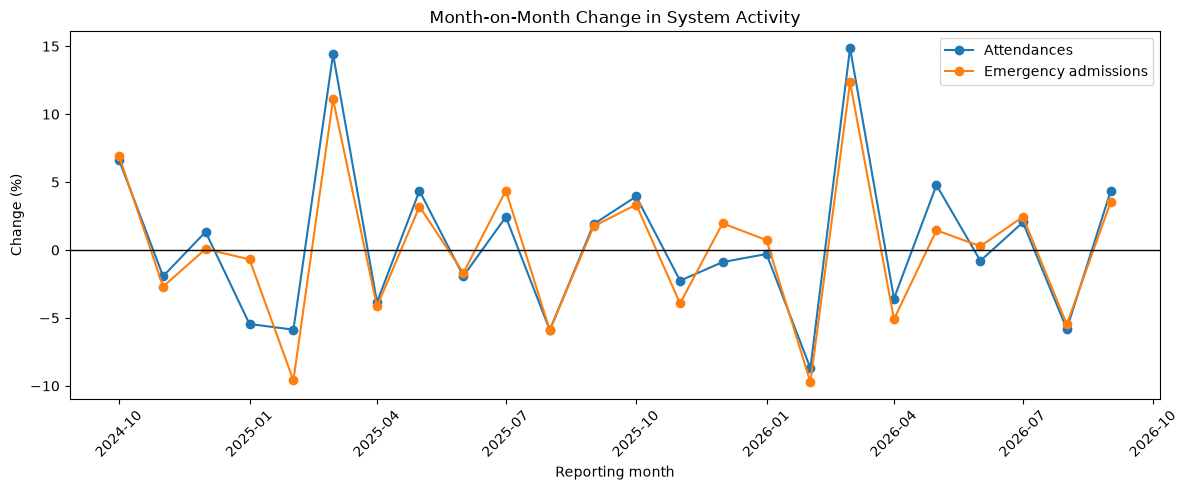

In [103]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    monthly_change["reporting_month"],
    monthly_change["attendance_monthly_change"],
    marker="o",
    label="Attendances",
)

ax.plot(
    monthly_change["reporting_month"],
    monthly_change["admission_monthly_change"],
    marker="o",
    label="Emergency admissions",
)

ax.axhline(
    0,
    color="black",
    linewidth=1,
)

ax.set_title("Month-on-Month Change in System Activity")
ax.set_xlabel("Reporting month")
ax.set_ylabel("Change (%)")
ax.legend()
ax.tick_params(axis="x", rotation=45)

fig.tight_layout()
plt.show()

## 12. Year-on-year system change

Month-on-month change captures short-term volatility, while year-on-year change compares each reporting month with the same month one year earlier.

Because the analytical period begins in September 2024, valid year-on-year comparisons become available only after the first 12 months of observations.

Year-on-year change table

In [104]:
year_on_year_change = monthly_kpis[
    [
        "reporting_month",
        "attendance_year_on_year_change",
        "admission_year_on_year_change",
    ]
].copy()

year_on_year_change[
    [
        "attendance_year_on_year_change",
        "admission_year_on_year_change",
    ]
] *= 100

year_on_year_change

,reporting_month,attendance_year_on_year_change,admission_year_on_year_change
0,2024-09-01,NaN,NaN
1,2024-10-01,NaN,NaN
2,2024-11-01,NaN,NaN
3,2024-12-01,NaN,NaN
4,2025-01-01,NaN,NaN
5,2025-02-01,NaN,NaN
6,2025-03-01,NaN,NaN
7,2025-04-01,NaN,NaN
8,2025-05-01,NaN,NaN
9,2025-06-01,NaN,NaN


Validate YoY availability

In [105]:
yoy_valid = year_on_year_change.dropna(
    subset=[
        "attendance_year_on_year_change",
        "admission_year_on_year_change",
    ]
)

assert len(yoy_valid) == 13

print("YEAR-ON-YEAR COMPARISON GATE: PASS")
print("Comparable months:", len(yoy_valid))
print(
    "First comparison:",
    yoy_valid["reporting_month"].min().date(),
)
print(
    "Last comparison:",
    yoy_valid["reporting_month"].max().date(),
)

yoy_valid

YEAR-ON-YEAR COMPARISON GATE: PASS
Comparable months: 13
First comparison: 2025-09-01
Last comparison: 2026-09-01


,reporting_month,attendance_year_on_year_change,admission_year_on_year_change
12,2025-09-01,4.3358,0.8960
13,2025-10-01,1.7255,-2.4582
14,2025-11-01,1.3844,-3.6971
15,2025-12-01,-0.8438,-1.8828
16,2026-01-01,4.5609,-0.4809
17,2026-02-01,1.4070,-0.6208
18,2026-03-01,1.8086,0.5013
19,2026-04-01,2.0853,-0.4865
20,2026-05-01,2.4971,-2.1734
21,2026-06-01,3.6709,-0.2217


YoY visualisation

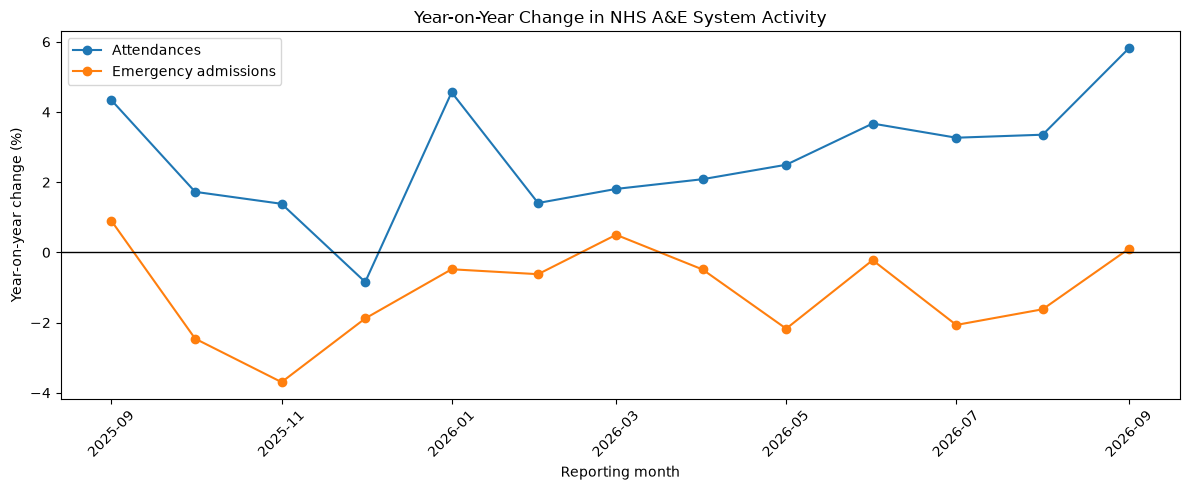

In [106]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    yoy_valid["reporting_month"],
    yoy_valid["attendance_year_on_year_change"],
    marker="o",
    label="Attendances",
)

ax.plot(
    yoy_valid["reporting_month"],
    yoy_valid["admission_year_on_year_change"],
    marker="o",
    label="Emergency admissions",
)

ax.axhline(
    0,
    color="black",
    linewidth=1,
)

ax.set_title("Year-on-Year Change in NHS A&E System Activity")
ax.set_xlabel("Reporting month")
ax.set_ylabel("Year-on-year change (%)")
ax.legend()
ax.tick_params(axis="x", rotation=45)

fig.tight_layout()
plt.show()

## 13. Four-hour breach pressure

The analysis now moves from overall activity volumes to system-pressure measures.

`four_hour_breaches` combines the controlled six four-hour breach source measures defined in the transformation layer and aggregated through the reconciled `analytics.monthly_pressure` SQL view.

The analysis examines absolute monthly breach volume first, followed by month-on-month and year-on-year movement.

Four-hour breach descriptive summary

In [107]:
breach_summary = monthly_pressure[
    "four_hour_breaches"
].agg(
    [
        "min",
        "max",
        "mean",
        "median",
        "std",
        "sum",
    ]
)

breach_min = monthly_pressure.loc[
    monthly_pressure["four_hour_breaches"].idxmin(),
    [
        "reporting_month",
        "four_hour_breaches",
    ],
]

breach_max = monthly_pressure.loc[
    monthly_pressure["four_hour_breaches"].idxmax(),
    [
        "reporting_month",
        "four_hour_breaches",
    ],
]

print("=== FOUR-HOUR BREACH SUMMARY ===")
display(breach_summary)

print("\nMinimum month:")
display(breach_min)

print("\nMaximum month:")
display(breach_max)

=== FOUR-HOUR BREACH SUMMARY ===


min         541,542.0000
max         677,473.0000
mean        594,566.1600
median      597,323.0000
std          34,165.4263
sum      14,864,154.0000
Name: four_hour_breaches, dtype: float64


Minimum month:


reporting_month       2026-04-01 00:00:00
four_hour_breaches           541,542.0000
Name: 19, dtype: object


Maximum month:


reporting_month       2024-12-01 00:00:00
four_hour_breaches           677,473.0000
Name: 3, dtype: object

four-hour breach trend

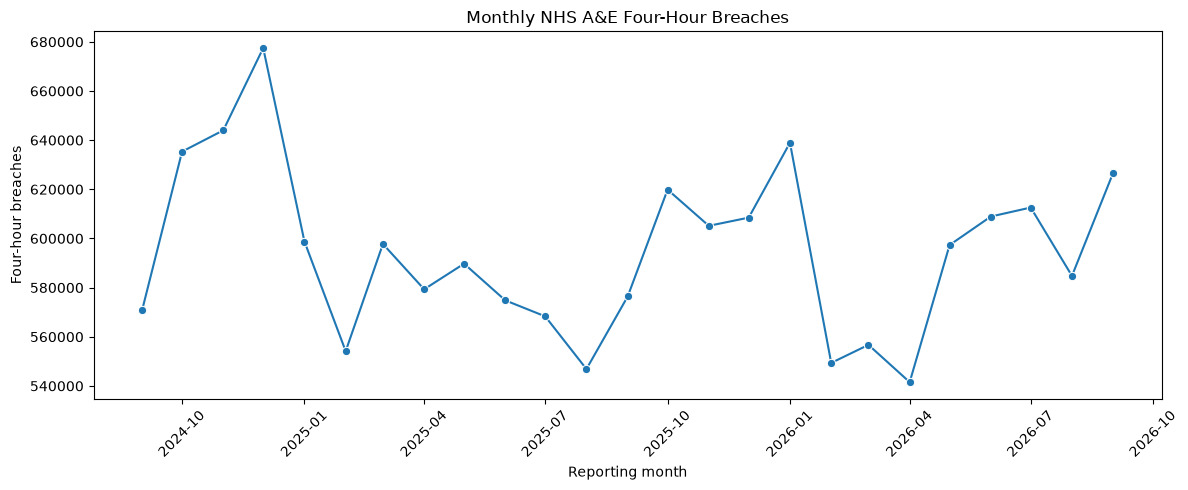

In [108]:
fig, ax = plt.subplots(figsize=(12, 5))

sns.lineplot(
    data=monthly_pressure,
    x="reporting_month",
    y="four_hour_breaches",
    marker="o",
    ax=ax,
)

ax.set_title("Monthly NHS A&E Four-Hour Breaches")
ax.set_xlabel("Reporting month")
ax.set_ylabel("Four-hour breaches")
ax.tick_params(axis="x", rotation=45)

fig.tight_layout()
plt.show()

breach change rates

In [109]:
breach_changes = monthly_pressure[
    [
        "reporting_month",
        "four_hour_breaches_monthly_change",
        "four_hour_breaches_year_on_year_change",
    ]
].copy()

breach_changes[
    [
        "four_hour_breaches_monthly_change",
        "four_hour_breaches_year_on_year_change",
    ]
] *= 100

breach_changes

,reporting_month,four_hour_breaches_monthly_change,four_hour_breaches_year_on_year_change
0,2024-09-01,NaN,NaN
1,2024-10-01,11.2901,NaN
2,2024-11-01,1.3621,NaN
3,2024-12-01,5.1983,NaN
4,2025-01-01,-11.6207,NaN
5,2025-02-01,-7.4489,NaN
6,2025-03-01,7.8683,NaN
7,2025-04-01,-3.0826,NaN
8,2025-05-01,1.7974,NaN
9,2025-06-01,-2.5310,NaN


breach change visualisation

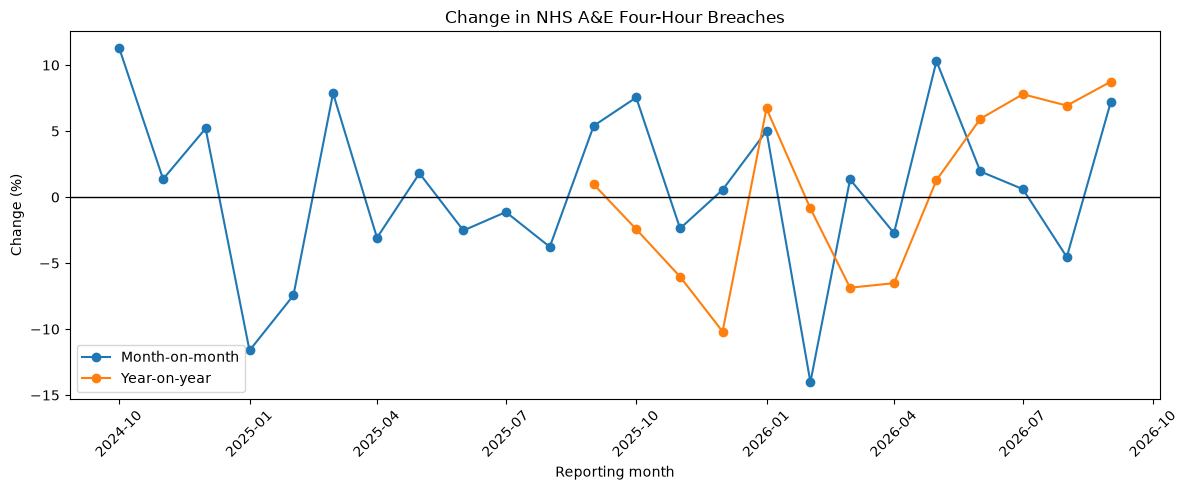

In [110]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    breach_changes["reporting_month"],
    breach_changes["four_hour_breaches_monthly_change"],
    marker="o",
    label="Month-on-month",
)

ax.plot(
    breach_changes["reporting_month"],
    breach_changes["four_hour_breaches_year_on_year_change"],
    marker="o",
    label="Year-on-year",
)

ax.axhline(
    0,
    color="black",
    linewidth=1,
)

ax.set_title("Change in NHS A&E Four-Hour Breaches")
ax.set_xlabel("Reporting month")
ax.set_ylabel("Change (%)")
ax.legend()
ax.tick_params(axis="x", rotation=45)

fig.tight_layout()
plt.show()

## 14. Decision-to-Admit Waiting Pressure

Decision-to-admit (DTA) waiting measures provide a separate view of patient-flow pressure.

This section examines three controlled measures:

- DTA waits of 4 to 12 hours
- DTA waits of 12 hours or more
- Total DTA waits of 4 hours or more

The two waiting-duration categories are retained separately so that movement in longer waits is not hidden within the combined total.

The analysis first describes the distribution and monthly trend of these measures, then identifies the months with the highest recorded waiting volumes.

DTA descriptive statistics

In [111]:
dta_columns = [
    "dta_waits_4_12hrs",
    "dta_waits_12plus_hrs",
    "total_dta_waits_4plus_hrs",
]

dta_summary = (
    monthly_pressure[dta_columns]
    .agg(
        [
            "min",
            "max",
            "mean",
            "median",
            "std",
            "sum",
        ]
    )
    .T
)

dta_summary

,min,max,mean,median,std,sum
dta_waits_4_12hrs,"73,599.0000","100,482.0000","84,656.8800","83,614.0000","7,750.5766","2,116,422.0000"
dta_waits_12plus_hrs,"35,467.0000","71,517.0000","48,230.7200","47,623.0000","7,712.7361","1,205,768.0000"
total_dta_waits_4plus_hrs,"115,542.0000","161,141.0000","132,887.6000","130,632.0000","12,571.5201","3,322,190.0000"


DTA absolute trend

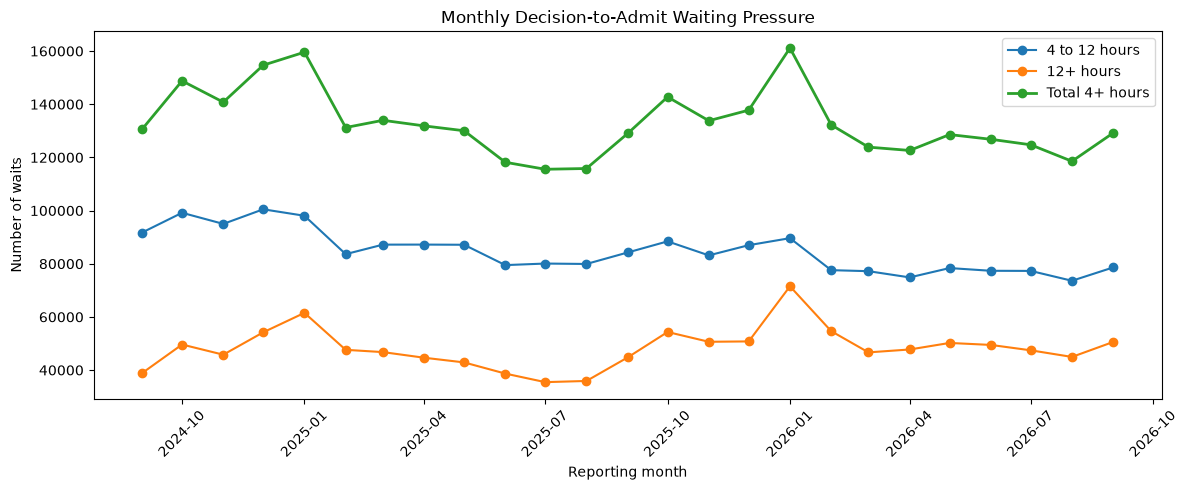

In [112]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    monthly_pressure["reporting_month"],
    monthly_pressure["dta_waits_4_12hrs"],
    marker="o",
    label="4 to 12 hours",
)

ax.plot(
    monthly_pressure["reporting_month"],
    monthly_pressure["dta_waits_12plus_hrs"],
    marker="o",
    label="12+ hours",
)

ax.plot(
    monthly_pressure["reporting_month"],
    monthly_pressure["total_dta_waits_4plus_hrs"],
    marker="o",
    linewidth=2,
    label="Total 4+ hours",
)

ax.set_title("Monthly Decision-to-Admit Waiting Pressure")
ax.set_xlabel("Reporting month")
ax.set_ylabel("Number of waits")
ax.legend()
ax.tick_params(axis="x", rotation=45)

fig.tight_layout()
plt.show()

identify DTA peak months

In [113]:
dta_peaks = pd.DataFrame(
    {
        "measure": [
            "DTA waits 4 to 12 hours",
            "DTA waits 12+ hours",
            "Total DTA waits 4+ hours",
        ],
        "peak_month": [
            monthly_pressure.loc[
                monthly_pressure["dta_waits_4_12hrs"].idxmax(),
                "reporting_month",
            ],
            monthly_pressure.loc[
                monthly_pressure["dta_waits_12plus_hrs"].idxmax(),
                "reporting_month",
            ],
            monthly_pressure.loc[
                monthly_pressure[
                    "total_dta_waits_4plus_hrs"
                ].idxmax(),
                "reporting_month",
            ],
        ],
        "peak_value": [
            monthly_pressure["dta_waits_4_12hrs"].max(),
            monthly_pressure["dta_waits_12plus_hrs"].max(),
            monthly_pressure["total_dta_waits_4plus_hrs"].max(),
        ],
    }
)

assert len(dta_peaks) == 3
assert dta_peaks["peak_month"].notna().all()

dta_peaks

,measure,peak_month,peak_value
0,DTA waits 4 to 12 hours,2024-12-01,"100,482.0000"
1,DTA waits 12+ hours,2026-01-01,"71,517.0000"
2,Total DTA waits 4+ hours,2026-01-01,"161,141.0000"


## 15. September 2025 to September 2026 System Comparison

The 25-month analytical period contains two September observations separated by 12 months.

This section compares September 2025 with September 2026 across:

- total A&E attendances
- emergency admissions
- four-hour breaches
- DTA waits of 4 to 12 hours
- DTA waits of 12 hours or more
- total DTA waits of 4 hours or more

Both absolute and percentage changes will be calculated.

This provides a consistent year-on-year system comparison while keeping activity and pressure measures visible together. The results are descriptive and do not establish causation.

In [114]:
comparison_months = pd.to_datetime(
    [
        "2025-09-01",
        "2026-09-01",
    ]
)

system_comparison = (
    monthly_kpis.loc[
        monthly_kpis["reporting_month"].isin(comparison_months),
        [
            "reporting_month",
            "total_attendances",
            "emergency_admissions",
        ],
    ]
    .merge(
        monthly_pressure.loc[
            monthly_pressure["reporting_month"].isin(
                comparison_months
            ),
            [
                "reporting_month",
                "four_hour_breaches",
                "dta_waits_4_12hrs",
                "dta_waits_12plus_hrs",
                "total_dta_waits_4plus_hrs",
            ],
        ],
        on="reporting_month",
        validate="one_to_one",
    )
    .sort_values("reporting_month")
    .reset_index(drop=True)
)

assert len(system_comparison) == 2

system_comparison

,reporting_month,total_attendances,emergency_admissions,four_hour_breaches,dta_waits_4_12hrs,dta_waits_12plus_hrs,total_dta_waits_4plus_hrs
0,2025-09-01,"2,310,222.0000","535,580.0000","576,391.0000","84,239.0000","44,765.0000","129,004.0000"
1,2026-09-01,"2,444,743.0000","536,158.0000","626,751.0000","78,617.0000","50,582.0000","129,199.0000"


year-on-year system comparison

In [115]:
comparison_measures = [
    "total_attendances",
    "emergency_admissions",
    "four_hour_breaches",
    "dta_waits_4_12hrs",
    "dta_waits_12plus_hrs",
    "total_dta_waits_4plus_hrs",
]

comparison_rows = []

for measure in comparison_measures:
    sep_2025 = system_comparison.loc[0, measure]
    sep_2026 = system_comparison.loc[1, measure]

    absolute_change = sep_2026 - sep_2025

    if sep_2025 == 0:
        percentage_change = float("nan")
    else:
        percentage_change = (
            absolute_change / sep_2025
        ) * 100

    comparison_rows.append(
        {
            "measure": measure,
            "sep_2025": sep_2025,
            "sep_2026": sep_2026,
            "absolute_change": absolute_change,
            "percentage_change": percentage_change,
        }
    )

system_year_change = pd.DataFrame(comparison_rows)

system_year_change

,measure,sep_2025,sep_2026,absolute_change,percentage_change
0,total_attendances,"2,310,222.0000","2,444,743.0000","134,521.0000",5.8229
1,emergency_admissions,"535,580.0000","536,158.0000",578.0000,0.1079
2,four_hour_breaches,"576,391.0000","626,751.0000","50,360.0000",8.7371
3,dta_waits_4_12hrs,"84,239.0000","78,617.0000","-5,622.0000",-6.6739
4,dta_waits_12plus_hrs,"44,765.0000","50,582.0000","5,817.0000",12.9945
5,total_dta_waits_4plus_hrs,"129,004.0000","129,199.0000",195.0000,0.1512


### September-to-September Interpretation

Between September 2025 and September 2026, total A&E attendances increased by 5.82%, while emergency admissions remained broadly stable with an increase of only 0.11%.

Four-hour breaches increased by 8.74%, exceeding the growth in attendance volume. This indicates that breach volume rose faster than overall activity during the comparison period, although the available data does not establish the operational causes of that change.

Total DTA waits of four hours or more were almost unchanged, increasing by only 0.15%. However, the composition of these waits changed:

- DTA waits of 4 to 12 hours decreased by 6.67%.
- DTA waits of 12 hours or more increased by 12.99%.

The near-stable combined DTA total therefore conceals a shift toward longer waits. This demonstrates why the two waiting-duration categories should be interpreted separately rather than relying only on the aggregate DTA measure.

combined analytical frame

In [116]:
system_analysis = monthly_kpis.loc[
    :,
    [
        "reporting_month",
        "total_attendances",
        "emergency_admissions",
    ],
].merge(
    monthly_pressure.loc[
        :,
        [
            "reporting_month",
            "four_hour_breaches",
            "dta_waits_4_12hrs",
            "dta_waits_12plus_hrs",
            "total_dta_waits_4plus_hrs",
        ],
    ],
    on="reporting_month",
    validate="one_to_one",
)

assert len(system_analysis) == 25
assert system_analysis["reporting_month"].is_unique
assert system_analysis.isna().sum().sum() == 0

print("COMBINED SYSTEM ANALYTICAL FRAME: PASS")
print("Rows:", len(system_analysis))
print("Columns:", len(system_analysis.columns))

system_analysis.head()

COMBINED SYSTEM ANALYTICAL FRAME: PASS
Rows: 25
Columns: 7


,reporting_month,total_attendances,emergency_admissions,four_hour_breaches,dta_waits_4_12hrs,dta_waits_12plus_hrs,total_dta_waits_4plus_hrs
0,2024-09-01,"2,214,217.0000","530,824.0000","570,888.0000","91,752.0000","38,880.0000","130,632.0000"
1,2024-10-01,"2,360,536.0000","567,448.0000","635,342.0000","99,172.0000","49,616.0000","148,788.0000"
2,2024-11-01,"2,314,998.0000","552,161.0000","643,996.0000","94,991.0000","45,791.0000","140,782.0000"
3,2024-12-01,"2,345,934.0000","552,592.0000","677,473.0000","100,482.0000","54,207.0000","154,689.0000"
4,2025-01-01,"2,218,130.0000","548,775.0000","598,746.0000","98,053.0000","61,529.0000","159,582.0000"


## 16. Relationship Between System Activity and Pressure

The previous sections examined activity and operational pressure separately. This section assesses how the monthly measures move in relation to one another across the 25-month analytical period.

The analysis considers:

- total A&E attendances
- emergency admissions
- four-hour breaches
- DTA waits of 4 to 12 hours
- DTA waits of 12 hours or more
- total DTA waits of 4 hours or more

Pearson correlation is used to describe the strength and direction of linear association between the monthly measures.

Correlation does not demonstrate causation. Any observed relationship may also reflect seasonality, capacity, case mix, operational conditions, or other factors not represented in this dataset.

Correlation matrix only

In [117]:
correlation_columns = [
    "total_attendances",
    "emergency_admissions",
    "four_hour_breaches",
    "dta_waits_4_12hrs",
    "dta_waits_12plus_hrs",
    "total_dta_waits_4plus_hrs",
]

correlation_matrix = system_analysis[
    correlation_columns
].corr(method="pearson")

assert correlation_matrix.shape == (6, 6)

correlation_matrix.round(3)

,total_attendances,emergency_admissions,four_hour_breaches,dta_waits_4_12hrs,dta_waits_12plus_hrs,total_dta_waits_4plus_hrs
total_attendances,1.0000,0.6420,0.3690,-0.2330,-0.0880,-0.1980
emergency_admissions,0.6420,1.0000,0.5770,0.4850,0.0670,0.3400
four_hour_breaches,0.3690,0.5770,1.0000,0.6090,0.4970,0.6800
dta_waits_4_12hrs,-0.2330,0.4850,0.6090,1.0000,0.3220,0.8140
dta_waits_12plus_hrs,-0.0880,0.0670,0.4970,0.3220,1.0000,0.8120
total_dta_waits_4plus_hrs,-0.1980,0.3400,0.6800,0.8140,0.8120,1.0000


correlation heatmap

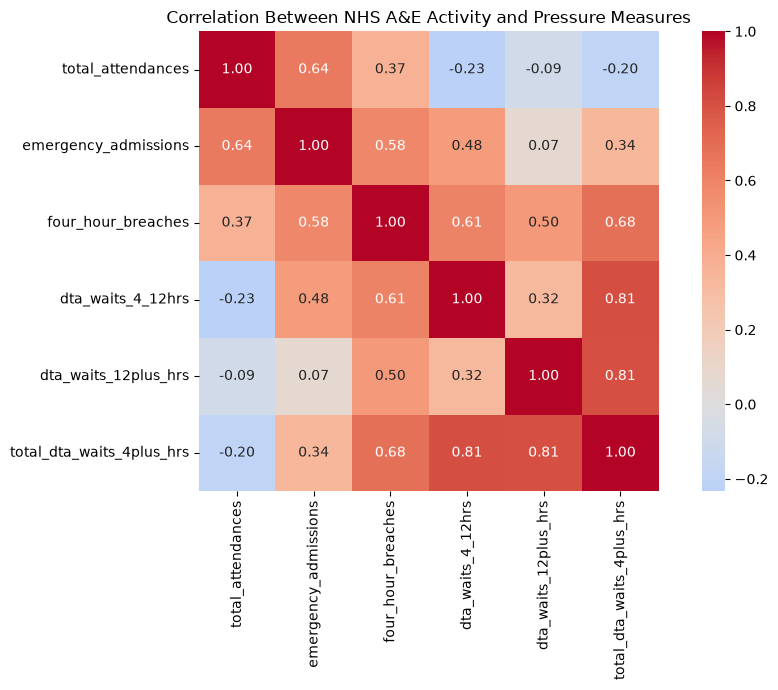

In [118]:
fig, ax = plt.subplots(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True,
    ax=ax,
)

ax.set_title(
    "Correlation Between NHS A&E Activity and Pressure Measures"
)

fig.tight_layout()
plt.show()


### Correlation Interpretation

The 25 monthly observations show several positive associations between system activity and pressure:

- Total attendances and emergency admissions have a moderate positive correlation of 0.64.
- Emergency admissions and four-hour breaches have a moderate positive correlation of 0.58.
- Four-hour breaches and DTA waits of 4 to 12 hours have a moderate positive correlation of 0.61.
- Four-hour breaches and DTA waits of 12 hours or more have a moderate positive correlation of 0.50.
- Four-hour breaches and total DTA waits of 4 hours or more have a moderately strong positive correlation of 0.68.

Total attendances have weaker relationships with the DTA measures:

- −0.23 with DTA waits of 4 to 12 hours
- −0.09 with DTA waits of 12 hours or more
- −0.20 with total DTA waits of 4 hours or more

The correlations of total DTA waits with its two component measures are both approximately 0.81. These values should not be treated as independent findings because the total DTA measure is calculated directly from the 4-to-12-hour and 12-plus-hour components.

The correlations describe association across 25 monthly observations. The results do not establish causation and may be influenced by seasonality, underlying time trends, capacity, case mix, or operational conditions not included in the dataset.

month-to-month change frame

In [119]:
change_analysis = monthly_kpis.loc[
    :,
    [
        "reporting_month",
        "attendance_monthly_change",
        "admission_monthly_change",
    ],
].merge(
    monthly_pressure.loc[
        :,
        [
            "reporting_month",
            "four_hour_breaches_monthly_change",
            "dta_waits_4_12hrs_monthly_change",
            "dta_waits_12plus_hrs_monthly_change",
            "total_dta_waits_4plus_hrs_monthly_change",
        ],
    ],
    on="reporting_month",
    validate="one_to_one",
)

change_analysis = (
    change_analysis
    .dropna()
    .reset_index(drop=True)
)

assert len(change_analysis) == 24
assert change_analysis.isna().sum().sum() == 0

print("MONTHLY CHANGE ANALYTICAL FRAME: PASS")
print("Rows:", len(change_analysis))
print("Columns:", len(change_analysis.columns))

change_analysis.head()

MONTHLY CHANGE ANALYTICAL FRAME: PASS
Rows: 24
Columns: 7


,reporting_month,attendance_monthly_change,admission_monthly_change,four_hour_breaches_monthly_change,dta_waits_4_12hrs_monthly_change,dta_waits_12plus_hrs_monthly_change,total_dta_waits_4plus_hrs_monthly_change
0,2024-10-01,0.0661,0.0690,0.1129,0.0809,0.2761,0.1390
1,2024-11-01,-0.0193,-0.0269,0.0136,-0.0422,-0.0771,-0.0538
2,2024-12-01,0.0134,0.0008,0.0520,0.0578,0.1838,0.0988
3,2025-01-01,-0.0545,-0.0069,-0.1162,-0.0242,0.1351,0.0316
4,2025-02-01,-0.0586,-0.0960,-0.0745,-0.1473,-0.2260,-0.1776


Monthly-change correlation matrix

In [120]:
change_correlation_columns = [
    "attendance_monthly_change",
    "admission_monthly_change",
    "four_hour_breaches_monthly_change",
    "dta_waits_4_12hrs_monthly_change",
    "dta_waits_12plus_hrs_monthly_change",
    "total_dta_waits_4plus_hrs_monthly_change",
]

change_correlation_matrix = change_analysis[
    change_correlation_columns
].corr(method="pearson")

assert change_correlation_matrix.shape == (6, 6)

change_correlation_matrix.round(3)

,attendance_monthly_change,admission_monthly_change,four_hour_breaches_monthly_change,dta_waits_4_12hrs_monthly_change,dta_waits_12plus_hrs_monthly_change,total_dta_waits_4plus_hrs_monthly_change
attendance_monthly_change,1.0000,0.9450,0.7310,0.6050,0.2010,0.3830
admission_monthly_change,0.9450,1.0000,0.6860,0.6970,0.3210,0.5000
four_hour_breaches_monthly_change,0.7310,0.6860,1.0000,0.8210,0.5950,0.7330
dta_waits_4_12hrs_monthly_change,0.6050,0.6970,0.8210,1.0000,0.7410,0.9040
dta_waits_12plus_hrs_monthly_change,0.2010,0.3210,0.5950,0.7410,1.0000,0.9560
total_dta_waits_4plus_hrs_monthly_change,0.3830,0.5000,0.7330,0.9040,0.9560,1.0000


Change-correlation heatmap

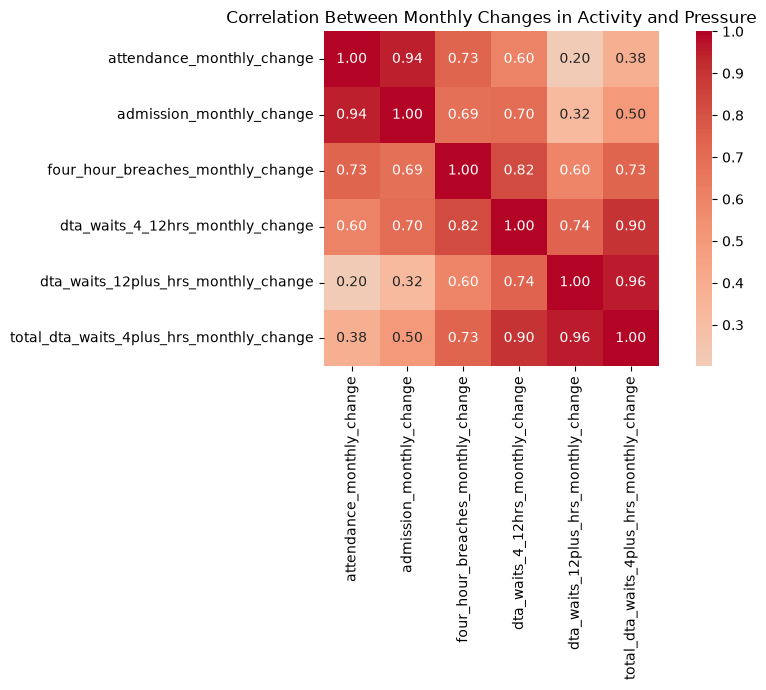

In [121]:
fig, ax = plt.subplots(figsize=(10, 7))

sns.heatmap(
    change_correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True,
    ax=ax,
)

ax.set_title(
    "Correlation Between Monthly Changes in Activity and Pressure"
)

fig.tight_layout()
plt.show()

### Monthly-Change Correlation Interpretation

The monthly-change analysis examines whether activity and pressure measures increased or decreased together between consecutive reporting months.

The strongest relationship is between attendance change and emergency-admission change, with a correlation of 0.94. This indicates that monthly movement in the two activity measures was closely aligned across the observed transitions.

Four-hour breach change also has positive relationships with:

- attendance change: 0.73
- emergency-admission change: 0.69
- DTA 4-to-12-hour change: 0.82
- DTA 12-plus-hour change: 0.60

Attendance change has a weaker relationship with DTA 12-plus-hour change, at 0.20. This suggests that movements in the longest DTA waits were less closely aligned with monthly attendance changes than the other pressure measures.

The correlations involving total DTA change and its two components should not be interpreted as independent findings. Total DTA waits are calculated directly from the 4-to-12-hour and 12-plus-hour categories.

These associations are based on 24 month-to-month transitions. Correlation indicates co-movement, not causation, and does not account for seasonality, capacity, case mix, or other operational factors.

Statistical significance test

In [122]:
from scipy.stats import pearsonr

relationship_pairs = [
    (
        "attendance_monthly_change",
        "admission_monthly_change",
    ),
    (
        "attendance_monthly_change",
        "four_hour_breaches_monthly_change",
    ),
    (
        "attendance_monthly_change",
        "dta_waits_4_12hrs_monthly_change",
    ),
    (
        "attendance_monthly_change",
        "dta_waits_12plus_hrs_monthly_change",
    ),
    (
        "admission_monthly_change",
        "four_hour_breaches_monthly_change",
    ),
    (
        "four_hour_breaches_monthly_change",
        "dta_waits_4_12hrs_monthly_change",
    ),
    (
        "four_hour_breaches_monthly_change",
        "dta_waits_12plus_hrs_monthly_change",
    ),
]

statistical_results = []

for first_measure, second_measure in relationship_pairs:
    correlation, p_value = pearsonr(
        change_analysis[first_measure],
        change_analysis[second_measure],
    )

    statistical_results.append(
        {
            "first_measure": first_measure,
            "second_measure": second_measure,
            "pearson_correlation": correlation,
            "p_value": p_value,
            "significant_at_0_05": p_value < 0.05,
        }
    )

relationship_tests = pd.DataFrame(statistical_results)

relationship_tests

,first_measure,second_measure,pearson_correlation,p_value,significant_at_0_05
0,attendance_monthly_change,admission_monthly_change,0.9446,0.0000,True
1,attendance_monthly_change,four_hour_breaches_monthly_change,0.7313,0.0000,True
2,attendance_monthly_change,dta_waits_4_12hrs_monthly_change,0.6050,0.0017,True
3,attendance_monthly_change,dta_waits_12plus_hrs_monthly_change,0.2012,0.3459,False
4,admission_monthly_change,four_hour_breaches_monthly_change,0.6864,0.0002,True
5,four_hour_breaches_monthly_change,dta_waits_4_12hrs_monthly_change,0.8207,0.0000,True
6,four_hour_breaches_monthly_change,dta_waits_12plus_hrs_monthly_change,0.5950,0.0022,True


### Statistical Relationship Findings

Pearson correlation tests were applied to seven selected month-to-month relationships across the 24 comparable monthly transitions.

Six relationships had p-values below 0.05.

The strongest observed relationship was between monthly attendance change and emergency-admission change (r = 0.945). Monthly four-hour breach change was also positively associated with attendance change (r = 0.731), emergency-admission change (r = 0.686), DTA 4-to-12-hour change (r = 0.821), and DTA 12-plus-hour change (r = 0.595).

Attendance change and DTA 4-to-12-hour change were positively associated (r = 0.605).

In contrast, the relationship between attendance change and DTA 12-plus-hour change was weak (r = 0.202) and was not statistically significant at the 0.05 level (p = 0.346).

These results indicate statistical co-movement within the observed 24 monthly transitions. They do not establish that changes in one measure caused changes in another. The analysis does not control for seasonality, capacity, case mix, staffing, bed availability, or other operational factors.

identify largest monthly movements

In [123]:
movement_columns = {
    "Attendances": "attendance_monthly_change",
    "Emergency admissions": "admission_monthly_change",
    "Four-hour breaches": "four_hour_breaches_monthly_change",
    "DTA 4 to 12 hours": "dta_waits_4_12hrs_monthly_change",
    "DTA 12+ hours": "dta_waits_12plus_hrs_monthly_change",
}

largest_movements = []

for measure, column in movement_columns.items():
    maximum_index = change_analysis[column].idxmax()
    minimum_index = change_analysis[column].idxmin()

    largest_movements.append(
        {
            "measure": measure,
            "largest_increase_month": change_analysis.loc[
                maximum_index,
                "reporting_month",
            ],
            "largest_increase_pct": (
                change_analysis.loc[maximum_index, column] * 100
            ),
            "largest_decrease_month": change_analysis.loc[
                minimum_index,
                "reporting_month",
            ],
            "largest_decrease_pct": (
                change_analysis.loc[minimum_index, column] * 100
            ),
        }
    )

largest_movements = pd.DataFrame(largest_movements)

largest_movements

,measure,largest_increase_month,largest_increase_pct,largest_decrease_month,largest_decrease_pct
0,Attendances,2026-03-01,14.8680,2026-02-01,-8.7029
1,Emergency admissions,2026-03-01,12.3479,2026-02-01,-9.7267
2,Four-hour breaches,2024-10-01,11.2901,2026-02-01,-14.0189
3,DTA 4 to 12 hours,2024-10-01,8.0870,2025-02-01,-14.7257
4,DTA 12+ hours,2026-01-01,40.8120,2026-02-01,-23.5860


## 17. Largest Monthly Movements

The largest month-to-month movements were concentrated in a small number of reporting periods.

Attendances and emergency admissions both recorded their largest decreases in February 2026, followed by their largest increases in March 2026. Four-hour breaches also recorded their largest decrease in February 2026.

The largest increase in DTA waits of 12 hours or more occurred in January 2026, when the measure rose by 40.81% from the preceding month. The largest decrease followed in February 2026, at 23.59%.

DTA waits of 4 to 12 hours followed a different pattern. The largest increase occurred in October 2024, while the largest decrease occurred in February 2025.

These movements identify periods suitable for more detailed investigation. The current dataset does not contain sufficient operational information to attribute the changes to specific causes.

focused high-movement period table

In [124]:
focus_start = pd.Timestamp("2025-12-01")
focus_end = pd.Timestamp("2026-03-01")

high_movement_period = system_analysis.loc[
    system_analysis["reporting_month"].between(
        focus_start,
        focus_end,
    )
].copy()

assert len(high_movement_period) == 4

high_movement_period

,reporting_month,total_attendances,emergency_admissions,four_hour_breaches,dta_waits_4_12hrs,dta_waits_12plus_hrs,total_dta_waits_4plus_hrs
15,2025-12-01,"2,326,139.0000","542,188.0000","608,475.0000","86,988.0000","50,789.0000","137,777.0000"
16,2026-01-01,"2,319,296.0000","546,136.0000","638,938.0000","89,624.0000","71,517.0000","161,141.0000"
17,2026-02-01,"2,117,450.0000","493,015.0000","549,366.0000","77,589.0000","54,649.0000","132,238.0000"
18,2026-03-01,"2,432,272.0000","553,892.0000","556,711.0000","77,205.0000","46,665.0000","123,870.0000"


focused-period percentage changes

In [125]:
focus_measures = [
    "total_attendances",
    "emergency_admissions",
    "four_hour_breaches",
    "dta_waits_4_12hrs",
    "dta_waits_12plus_hrs",
    "total_dta_waits_4plus_hrs",
]

focused_changes = high_movement_period[
    ["reporting_month", *focus_measures]
].copy()

focused_changes[focus_measures] = (
    focused_changes[focus_measures]
    .pct_change()
    .mul(100)
)

focused_changes = (
    focused_changes
    .dropna()
    .reset_index(drop=True)
)

assert len(focused_changes) == 3

focused_changes

,reporting_month,total_attendances,emergency_admissions,four_hour_breaches,dta_waits_4_12hrs,dta_waits_12plus_hrs,total_dta_waits_4plus_hrs
0,2026-01-01,-0.2942,0.7282,5.0065,3.0303,40.8120,16.9578
1,2026-02-01,-8.7029,-9.7267,-14.0189,-13.4283,-23.5860,-17.9365
2,2026-03-01,14.8680,12.3479,1.3370,-0.4949,-14.6096,-6.3280


### Focused High-Movement Period

The December 2025 to March 2026 period shows that activity and pressure measures did not always move proportionately.

From December 2025 to January 2026, total attendances were broadly stable, decreasing by approximately 0.29%, while four-hour breaches increased by 5.01%. This period also contained the observed peak in DTA waits of 12 hours or more.

February 2026 recorded substantial decreases across several measures compared with January:

- total attendances decreased by 8.70%
- emergency admissions decreased by 9.73%
- four-hour breaches decreased by 14.02%
- DTA waits of 4 to 12 hours decreased by 13.43%

March 2026 then recorded a strong rebound in activity. Total attendances increased by 14.87% and emergency admissions increased by 12.35%, while four-hour breaches increased by only 1.34%. DTA waits of 4 to 12 hours remained broadly stable, decreasing by approximately 0.49%.

The differing scale of these movements indicates that activity volume and pressure did not move proportionately in every month. Additional operational data would be required to investigate the reasons for these differences.

Final analytical validation

In [126]:
assert len(monthly_kpis) == 25
assert len(monthly_pressure) == 25
assert len(system_analysis) == 25
assert len(change_analysis) == 24
assert len(system_year_change) == 6
assert len(relationship_tests) == 7
assert len(largest_movements) == 5
assert len(high_movement_period) == 4
assert len(focused_changes) == 3

assert monthly_kpis["reporting_month"].is_unique
assert monthly_pressure["reporting_month"].is_unique
assert system_analysis["reporting_month"].is_unique

assert system_analysis.isna().sum().sum() == 0
assert change_analysis.isna().sum().sum() == 0

print("SYSTEM PERFORMANCE NOTEBOOK VALIDATION: PASS")
print("Reporting months:", len(system_analysis))
print("Monthly transitions:", len(change_analysis))
print("Year-on-year measures:", len(system_year_change))
print("Statistical relationships tested:", len(relationship_tests))

SYSTEM PERFORMANCE NOTEBOOK VALIDATION: PASS
Reporting months: 25
Monthly transitions: 24
Year-on-year measures: 6
Statistical relationships tested: 7


## 18. Key Findings

### Activity

A&E attendance volume varied substantially across the 25-month analytical period.

Between September 2025 and September 2026, total attendances increased by 5.82%, while emergency admissions increased by only 0.11%.

### Four-Hour Pressure

Four-hour breaches increased by 8.74% between September 2025 and September 2026. This increase exceeded the growth in attendance volume over the same comparison period.

Month-to-month changes in four-hour breaches were positively associated with changes in attendances, emergency admissions, and DTA waiting measures.

### Decision-to-Admit Pressure

Total DTA waits of four hours or more increased by only 0.15% between September 2025 and September 2026. However, this aggregate result concealed a change in composition:

- DTA waits of 4 to 12 hours decreased by 6.67%.
- DTA waits of 12 hours or more increased by 12.99%.

The highest observed volume of DTA waits of 12 hours or more occurred in January 2026. The highest combined volume of DTA waits of four hours or more also occurred in January 2026.

### Activity and Pressure Relationships

Analysis of month-to-month changes identified positive co-movement between several activity and pressure measures.

Six of the seven selected Pearson relationships had p-values below 0.05.

The relationship between attendance change and DTA waits of 12 hours or more was weaker and was not statistically significant at the 0.05 level.

### High-Movement Period

The December 2025 to March 2026 period demonstrates that activity and pressure did not move proportionately in every month.

February 2026 recorded substantial reductions across activity and several pressure measures, followed by a strong rebound in attendances and emergency admissions in March 2026 without an equivalent rebound in four-hour breaches.

These findings describe observed system-level patterns and associations. They do not establish causal relationships.

## 19. Analytical Limitations

The findings should be interpreted within the scope of the available monthly dataset.

Key limitations include:

- The analysis uses aggregated monthly observations rather than patient-level or daily operational data.
- The analytical period contains 25 monthly observations and 24 month-to-month transitions.
- Correlation and statistical significance describe association rather than causation.
- The analysis does not control for staffing, bed availability, capacity, patient acuity, case mix, seasonal illness, operational policy, or other potential explanatory factors.
- Provider composition and organisation naming may change over time.
- Total DTA waits of four hours or more are derived from the 4-to-12-hour and 12-plus-hour categories. Correlations between the combined measure and its components are therefore not independent findings.
- Statistical findings should be considered alongside operational context and additional evidence before conclusions are drawn about causes or interventions.

## 20. Notebook Completion

This notebook has completed the system-level performance and pressure analysis for the validated September 2024 to September 2026 analytical period.

The analysis used the controlled DuckDB SQL layer and covered:

- attendance and emergency-admission trends
- month-on-month change
- year-on-year change
- four-hour breach pressure
- decision-to-admit waiting pressure
- September-to-September comparison
- activity-pressure correlations
- month-to-month change correlations
- selected statistical relationship tests
- high-movement period investigation

Provider-level variation and comparison should remain separate from this system-level notebook and be addressed in the next notebook in the established analytical sequence.